# Google Colab edition

Run the setup cell first, then work from top to bottom. Keep the course ZIP in My Drive. Use a fresh Colab runtime when switching dependency profiles. **Select a GPU runtime before running this notebook.** 

MIT instructor solution, with attribution retained. Colab adaptation replaces mandatory Comet logging with local logs. Lab 2 downloads the official teaching data. MNIST evaluation and GPU placement fixes are included; face-data experiments need a GPU and a large download.

Source: https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/e44754eac7a61d489fb07a68245bfbb290823228/lab2/solutions/TF_Part1_MNIST_Solution.ipynb

In [1]:
# Colab setup. Run this cell before the exercise cells.
from pathlib import Path
import os, sys, zipfile

USE_GOOGLE_DRIVE = True  #@param {type:"boolean"}
QUICK_RUN = False  #@param {type:"boolean"}
ARCHIVE_PATH = "/content/drive/MyDrive/HaiLong_Colab_Exercises_2026-10-03.zip"  #@param {type:"string"}

try:
    from google.colab import drive, files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    if USE_GOOGLE_DRIVE:
        if not Path('/content/drive/MyDrive').is_dir():
            drive.mount('/content/drive', timeout_ms=300000)
    COURSE_ROOT = Path('/content/HaiLong_Colab_Exercises')
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        archive = Path(ARCHIVE_PATH)
        if not archive.is_file():
            print('Select HaiLong_Colab_Exercises_2026-10-03.zip from your computer.')
            uploaded = files.upload()
            choices = [Path(n) for n in uploaded if n.endswith('.zip')]
            if len(choices) != 1:
                raise ValueError('Upload exactly one course ZIP file.')
            archive = choices[0]
        with zipfile.ZipFile(archive) as z:
            base = Path('/content').resolve()
            for member in z.infolist():
                target = (base / member.filename).resolve()
                if not target.is_relative_to(base) or not member.filename.startswith('HaiLong_Colab_Exercises/'):
                    raise ValueError('This is not the expected course archive.')
            z.extractall(base)
    if not (COURSE_ROOT / 'colab_runtime.py').is_file():
        raise FileNotFoundError('The ZIP must contain HaiLong_Colab_Exercises/colab_runtime.py.')
else:
    # Also permits local checks without assuming the current notebook directory.
    COURSE_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                        if (p / 'colab_runtime.py').is_file()), None)
    if COURSE_ROOT is None:
        raise RuntimeError('Open this notebook in Colab or run it inside the extracted course folder.')

os.environ['COURSE_SMOKE'] = '1' if QUICK_RUN else '0'
os.environ['WANDB_MODE'] = 'offline'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(COURSE_ROOT))
from colab_runtime import setup_course, finish_run
# Filled individually for each notebook by the builder.

COLAB_CONTEXT = setup_course(COURSE_ROOT, '02_mit_6s191', 'mit', '05_tf_lab2_mnist.ipynb', USE_GOOGLE_DRIVE, install=IN_COLAB)

Exercise folder: /content/HaiLong_Colab_Exercises/02_mit_6s191
Run mode: FULL EXERCISE
Results: /content/drive/MyDrive/HaiLong_Colab_Results/02_mit_6s191/results


In [2]:
from datetime import datetime, timezone
import json, uuid, platform, importlib.metadata, importlib.util
from pathlib import Path
assert not QUICK_RUN, "Full exercise completion requires QUICK_RUN=False."
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S') + '-' + uuid.uuid4().hex[:6]
RUN_DIR = Path('results') / Path(COLAB_CONTEXT['run']['notebook']).stem / RUN_ID
MODEL_DIR = Path('models') / Path(COLAB_CONTEXT['run']['notebook']).stem / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
TASK_EVIDENCE = {}
def record_task(name, **evidence):
    TASK_EVIDENCE[name] = evidence
    (RUN_DIR / 'task_evidence.json').write_text(json.dumps(TASK_EVIDENCE, indent=2, default=str))
def complete_notebook(required):
    missing = [key for key in required if key not in TASK_EVIDENCE]
    if missing:
        raise RuntimeError('Required exercise outputs are missing: ' + ', '.join(missing))
    COLAB_CONTEXT['run']['exercise_evidence'] = TASK_EVIDENCE
    COLAB_CONTEXT['run']['artifact_folder'] = str(RUN_DIR)
    COLAB_CONTEXT['run']['full_real_data_exercise_checks_passed'] = True
    COLAB_CONTEXT['run']['execution_environment'] = {
        'in_colab': IN_COLAB, 'python': platform.python_version(),
        'platform': platform.platform(), 'run_id': RUN_ID,
    }
    COLAB_CONTEXT['run']['execution_environment']['packages'] = {
        package: importlib.metadata.version(package)
        for package in ['numpy','pandas','tensorflow','torch','mitdeeplearning','transformers','peft']
        if importlib.util.find_spec(package.replace('-', '_')) is not None
    }
    finish_run(COLAB_CONTEXT)
    print('Required exercise checks passed. Artifacts:', RUN_DIR)

<table align="center">
  <td align="center"><a target="_blank" href="http://introtodeeplearning.com">
        <img src="https://i.ibb.co/Jr88sn2/mit.png" style="padding-bottom:5px;" />
      Visit MIT Deep Learning</a></td>
  <td align="center"><a target="_blank" href="https://colab.research.google.com/github/MITDeepLearning/introtodeeplearning/blob/master/lab2/solutions/TF_Part1_MNIST_Solution.ipynb">
        <img src="https://i.ibb.co/2P3SLwK/colab.png"  style="padding-bottom:5px;" />Run in Google Colab</a></td>
  <td align="center"><a target="_blank" href="https://github.com/MITDeepLearning/introtodeeplearning/blob/master/lab2/solutions/TF_Part1_MNIST_Solution.ipynb">
        <img src="https://i.ibb.co/xfJbPmL/github.png"  height="70px" style="padding-bottom:5px;"  />View Source on GitHub</a></td>
</table>

# Copyright Information

In [3]:
# Copyright 2026 MIT Introduction to Deep Learning. All Rights Reserved.
#
# Licensed under the MIT License. You may not use this file except in compliance
# with the License. Use and/or modification of this code outside of MIT Introduction
# to Deep Learning must reference:
#
# © MIT Introduction to Deep Learning
# http://introtodeeplearning.com
#

# Laboratory 2: Computer Vision

# Part 1: MNIST Digit Classification

In the first portion of this lab, we will build and train a convolutional neural network (CNN) for classification of handwritten digits from the famous [MNIST](http://yann.lecun.com/exdb/mnist/) dataset. The MNIST dataset consists of 60,000 training images and 10,000 test images. Our classes are the digits 0-9.

First, let's download the course repository, install dependencies, and import the relevant packages we'll need for this lab.

In [4]:
# Import Tensorflow 2.0
# !pip install tensorflow
import tensorflow as tf

# MIT introduction to deep learning package
# Dependencies installed in the first cell.
import mitdeeplearning as mdl

# other packages
import matplotlib.pyplot as plt
import numpy as np
import random
from tqdm import tqdm

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Training metrics are written to local CSV/JSON artifacts. No Comet account is needed.


In [5]:
# Dependencies installed in the first cell.
from types import SimpleNamespace
from colab_runtime import LocalExperiment
comet_ml = SimpleNamespace(init=lambda **kw: None, Experiment=LocalExperiment)
# TODO: ENTER YOUR API KEY HERE!!
COMET_API_KEY = ""

# Check that we are using a GPU, if not switch runtimes
#   using Runtime > Change Runtime Type > GPU
# GPU recommended; CPU also works for this small exercise.
# Logs are saved locally; no account key is needed.
assert tf.config.list_physical_devices('GPU'), 'Select a Colab GPU runtime for the full run.'
tf.keras.utils.set_random_seed(42)

In [6]:
# start a first comet experiment for the first part of the lab
comet_ml.init(project_name="6S191_lab2_part1_NN")
comet_model_1 = comet_ml.Experiment()

## 1.1 MNIST dataset

Let's download and load the dataset and display a few random samples from it:

In [7]:
mnist = tf.keras.datasets.mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
train_images = (np.expand_dims(train_images, axis=-1)/255.).astype(np.float32)
train_labels = (train_labels).astype(np.int64)
test_images = (np.expand_dims(test_images, axis=-1)/255.).astype(np.float32)
test_labels = (test_labels).astype(np.int64)
assert len(train_images)==60000 and len(test_images)==10000
record_task('real_mnist_data',train_examples=60000,test_examples=10000,synthetic=False)

       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   32768/11490434 ━━━━━━━━━━━━━━━━━━━━ 18s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 50s 4us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 57s 5us/step

  114688/11490434 ━━━━━━━━━━━━━━━━━━━━ 46s 4us/step

...

 6897664/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

 8093696/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 9060352/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

10174464/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Our training set is made up of 28x28 grayscale images of handwritten digits.

Let's visualize what some of these images and their corresponding training labels look like.

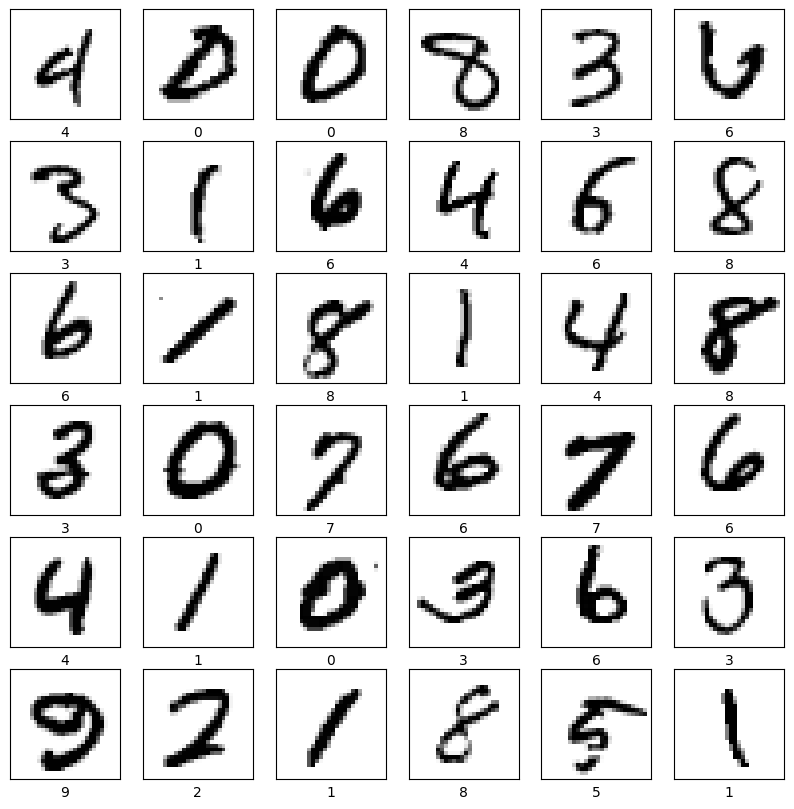

In [8]:
plt.figure(figsize=(10,10))
random_inds = np.random.choice(60000,36)
for i in range(36):
    plt.subplot(6,6,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    image_ind = random_inds[i]
    plt.imshow(np.squeeze(train_images[image_ind]), cmap=plt.cm.binary)
    plt.xlabel(train_labels[image_ind])
comet_model_1.log_figure(figure=plt)

## 1.2 Neural Network for Handwritten Digit Classification

We'll first build a simple neural network consisting of two fully connected layers and apply this to the digit classification task. Our network will ultimately output a probability distribution over the 10 digit classes (0-9). This first architecture we will be building is depicted below:

![alt_text](https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/master/lab2/img/mnist_2layers_arch.png "CNN Architecture for MNIST Classification")


### Fully connected neural network architecture
To define the architecture of this first fully connected neural network, we'll once again use the Keras API and define the model using the [`Sequential`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential) class. Note how we first use a [`Flatten`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Flatten) layer, which flattens the input so that it can be fed into the model.

In this next block, you'll define the fully connected layers of this simple work.

In [9]:
def build_fc_model():
  fc_model = tf.keras.Sequential([
      # First define a Flatten layer
      tf.keras.layers.Flatten(),

      # '''TODO: Define the activation function for the first fully connected (Dense) layer.'''
      tf.keras.layers.Dense(128, activation=tf.nn.relu),
      # tf.keras.layers.Dense(128, activation= '''TODO'''),

      # '''TODO: Define the second Dense layer to output the classification probabilities'''
      tf.keras.layers.Dense(10, activation=tf.nn.softmax)
      # [TODO Dense layer to output classification probabilities]

  ])
  return fc_model

model = build_fc_model()

As we progress through this next portion, you may find that you'll want to make changes to the architecture defined above. **Note that in order to update the model later on, you'll need to re-run the above cell to re-initialize the model.**

Let's take a step back and think about the network we've just created. The first layer in this network, `tf.keras.layers.Flatten`, transforms the format of the images from a 2d-array (28 x 28 pixels), to a 1d-array of 28 * 28 = 784 pixels. You can think of this layer as unstacking rows of pixels in the image and lining them up. There are no learned parameters in this layer; it only reformats the data.

After the pixels are flattened, the network consists of a sequence of two `tf.keras.layers.Dense` layers. These are fully-connected neural layers. The first `Dense` layer has 128 nodes (or neurons). The second (and last) layer (which you've defined!) should return an array of probability scores that sum to 1. Each node contains a score that indicates the probability that the current image belongs to one of the handwritten digit classes.

That defines our fully connected model!



### Compile the model

Before training the model, we need to define a few more settings. These are added during the model's [`compile`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#compile) step:

* *Loss function* — This defines how we measure how accurate the model is during training. As was covered in lecture, during training we want to minimize this function, which will "steer" the model in the right direction.
* *Optimizer* — This defines how the model is updated based on the data it sees and its loss function.
* *Metrics* — Here we can define metrics used to monitor the training and testing steps. In this example, we'll look at the *accuracy*, the fraction of the images that are correctly classified.

We'll start out by using a stochastic gradient descent (SGD) optimizer initialized with a learning rate of 0.1. Since we are performing a categorical classification task, we'll want to use the [cross entropy loss](https://www.tensorflow.org/api_docs/python/tf/keras/metrics/sparse_categorical_crossentropy).

You'll want to experiment with both the choice of optimizer and learning rate and evaluate how these affect the accuracy of the trained model.

In [10]:
import pandas as pd
def optimizer_from_config(config):
    return getattr(tf.keras.optimizers, config['optimizer'])(learning_rate=config['learning_rate'])

def choose_optimizer(model_factory, label):
    permutation = np.random.default_rng(42).permutation(60000)
    fitting, validation = permutation[:54000], permutation[54000:]
    comparisons = []
    for name, lr in [('SGD',.1),('SGD',.01),('Adam',.001)]:
        tf.keras.utils.set_random_seed(42)
        candidate = model_factory()
        config = dict(optimizer=name, learning_rate=lr)
        candidate.compile(optimizer=optimizer_from_config(config),
                          loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        history = candidate.fit(train_images[fitting], train_labels[fitting], batch_size=64,
                                epochs=2, verbose=2)
        val_loss, val_acc = candidate.evaluate(train_images[validation],train_labels[validation],verbose=0)
        comparisons.append(dict(**config, epochs=2, fitting_examples=54000, validation_examples=6000,
                                validation_loss=float(val_loss), validation_accuracy=float(val_acc)))
        pd.DataFrame(history.history).to_csv(RUN_DIR/f'{label}_{name}_{lr}_history.csv', index=False)
        del candidate
    table=pd.DataFrame(comparisons); table.to_csv(RUN_DIR/f'{label}_optimizer_comparison.csv',index=False)
    print(table.to_string(index=False))
    best=max(comparisons,key=lambda r:r['validation_accuracy'])
    record_task(label+'_optimizer_experiments', trials=comparisons, selected=best, test_set_used_for_selection=False)
    return best

best_fc=choose_optimizer(build_fc_model,'fc')
model=build_fc_model()
model.compile(optimizer=optimizer_from_config(best_fc),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

Epoch 1/2


844/844 - 6s - 7ms/step - accuracy: 0.8936 - loss: 0.3802


Epoch 2/2


844/844 - 3s - 4ms/step - accuracy: 0.9411 - loss: 0.2068


Epoch 1/2


...

844/844 - 5s - 6ms/step - accuracy: 0.9120 - loss: 0.3121


Epoch 2/2


844/844 - 3s - 3ms/step - accuracy: 0.9598 - loss: 0.1414


optimizer  learning_rate  epochs  fitting_examples  validation_examples  validation_loss  validation_accuracy
      SGD          0.100       2             54000                 6000         0.177976               0.9515
      SGD          0.010       2             54000                 6000         0.374188               0.9030
     Adam          0.001       2             54000                 6000         0.124617               0.9645


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Train the model

We're now ready to train our model, which will involve feeding the training data (`train_images` and `train_labels`) into the model, and then asking it to learn the associations between images and labels. We'll also need to define the batch size and the number of epochs, or iterations over the MNIST dataset, to use during training.

In Lab 1, we saw how we can use `GradientTape` to optimize losses and train models with stochastic gradient descent. After defining the model settings in the `compile` step, we can also accomplish training by calling the [`fit`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#fit) method on an instance of the `Model` class. We will use this to train our fully connected model


In [11]:
BATCH_SIZE=64; EPOCHS=5
fc_history=model.fit(train_images,train_labels,batch_size=BATCH_SIZE,epochs=EPOCHS,verbose=2)
pd.DataFrame(fc_history.history).to_csv(RUN_DIR/'fc_full_training.csv',index=False)
comet_model_1.end()

Epoch 1/5


938/938 - 4s - 5ms/step - accuracy: 0.9175 - loss: 0.2975


Epoch 2/5


938/938 - 2s - 3ms/step - accuracy: 0.9622 - loss: 0.1322


Epoch 3/5


938/938 - 4s - 4ms/step - accuracy: 0.9737 - loss: 0.0911


Epoch 4/5


938/938 - 4s - 4ms/step - accuracy: 0.9805 - loss: 0.0682


Epoch 5/5


938/938 - 2s - 3ms/step - accuracy: 0.9851 - loss: 0.0530


As the model trains, the loss and accuracy metrics are displayed. With five epochs and a learning rate of 0.01, this fully connected model should achieve an accuracy of approximatley 0.97 (or 97%) on the training data.

### Evaluate accuracy on the test dataset

Now that we've trained the model, we can ask it to make predictions about a test set that it hasn't seen before. In this example, the `test_images` array comprises our test dataset. To evaluate accuracy, we can check to see if the model's predictions match the labels from the `test_labels` array.

Use the [`evaluate`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#evaluate) method to evaluate the model on the test dataset!

In [12]:
fc_test_loss,fc_test_acc=model.evaluate(test_images,test_labels,verbose=0)
model.save(MODEL_DIR/'fc_mnist.keras')
record_task('fc_full_training_and_test',epochs=EPOCHS,train_examples=60000,test_examples=10000,
            test_loss=float(fc_test_loss),test_accuracy=float(fc_test_acc),checkpoint=str(MODEL_DIR/'fc_mnist.keras'))
print('Fully connected test accuracy:',fc_test_acc)

Fully connected test accuracy: 0.9742000102996826


You may observe that the accuracy on the test dataset is a little lower than the accuracy on the training dataset. This gap between training accuracy and test accuracy is an example of *overfitting*, when a machine learning model performs worse on new data than on its training data.

What is the highest accuracy you can achieve with this first fully connected model? Since the handwritten digit classification task is pretty straightforward, you may be wondering how we can do better...

![Deeper...](https://i.kym-cdn.com/photos/images/newsfeed/000/534/153/f87.jpg)

## 1.3 Convolutional Neural Network (CNN) for handwritten digit classification

As we saw in lecture, convolutional neural networks (CNNs) are particularly well-suited for a variety of tasks in computer vision, and have achieved near-perfect accuracies on the MNIST dataset. We will now build a CNN composed of two convolutional layers and pooling layers, followed by two fully connected layers, and ultimately output a probability distribution over the 10 digit classes (0-9). The CNN we will be building is depicted below:

![alt_text](https://raw.githubusercontent.com/MITDeepLearning/introtodeeplearning/master/lab2/img/convnet_fig.png "CNN Architecture for MNIST Classification")

### Define the CNN model

We'll use the same training and test datasets as before, and proceed similarly as our fully connected network to define and train our new CNN model. To do this we will explore two layers we have not encountered before: you can use  [`keras.layers.Conv2D` ](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Conv2D) to define convolutional layers and [`keras.layers.MaxPool2D`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/MaxPool2D) to define the pooling layers. Use the parameters shown in the network architecture above to define these layers and build the CNN model.

In [13]:
def build_cnn_model():
    cnn_model = tf.keras.Sequential([

        # TODO: Define the first convolutional layer
        tf.keras.layers.Conv2D(filters=24, kernel_size=(3,3), activation=tf.nn.relu),
        # tf.keras.layers.Conv2D('''TODO''')

        # TODO: Define the first max pooling layer
        tf.keras.layers.MaxPool2D(pool_size=(2,2)),
        # tf.keras.layers.MaxPool2D('''TODO''')

        # TODO: Define the second convolutional layer
        tf.keras.layers.Conv2D(filters=36, kernel_size=(3,3), activation=tf.nn.relu),
        # tf.keras.layers.Conv2D('''TODO''')

        # TODO: Define the second max pooling layer
        tf.keras.layers.MaxPool2D(pool_size=(2,2)),
        # tf.keras.layers.MaxPool2D('''TODO''')

        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation=tf.nn.relu),

        # TODO: Define the last Dense layer to output the classification
        # probabilities. Pay attention to the activation needed a probability
        # output
        tf.keras.layers.Dense(10, activation=tf.nn.softmax)
        # [TODO Dense layer to output classification probabilities]
    ])

    return cnn_model

cnn_model = build_cnn_model()
# Initialize the model by passing some data through
cnn_model.predict(train_images[[0]])
# Print the summary of the layers in the model.
print(cnn_model.summary())

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (1, 26, 26, 24)        │           240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (1, 13, 13, 24)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (1, 11, 11, 36)        │         7,812 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (1, 5, 5, 36)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (1, 900)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (1, 128)               │       115,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (1, 10)                │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 124,670 (486.99 KB)

 Trainable params: 124,670 (486.99 KB)

 Non-trainable params: 0 (0.00 B)

None


### Train and test the CNN model

Now, as before, we can define the loss function, optimizer, and metrics through the `compile` method. Compile the CNN model with an optimizer and learning rate of choice:

In [14]:
comet_model_2=comet_ml.Experiment()
best_cnn=choose_optimizer(build_cnn_model,'cnn')
cnn_model=build_cnn_model()
cnn_model.compile(optimizer=optimizer_from_config(best_cnn),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

Epoch 1/2


844/844 - 8s - 10ms/step - accuracy: 0.9110 - loss: 0.2786


Epoch 2/2


844/844 - 3s - 3ms/step - accuracy: 0.9778 - loss: 0.0740


Epoch 1/2


...

844/844 - 9s - 10ms/step - accuracy: 0.9416 - loss: 0.1960


Epoch 2/2


844/844 - 3s - 4ms/step - accuracy: 0.9821 - loss: 0.0579


optimizer  learning_rate  epochs  fitting_examples  validation_examples  validation_loss  validation_accuracy
      SGD          0.100       2             54000                 6000         0.073918             0.976667
      SGD          0.010       2             54000                 6000         0.200331             0.941167
     Adam          0.001       2             54000                 6000         0.050418             0.986000


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


As was the case with the fully connected model, we can train our CNN using the `fit` method via the Keras API.

In [15]:
cnn_history=cnn_model.fit(train_images,train_labels,batch_size=BATCH_SIZE,epochs=EPOCHS,verbose=2)
pd.DataFrame(cnn_history.history).to_csv(RUN_DIR/'cnn_full_training.csv',index=False)

Epoch 1/5


938/938 - 10s - 10ms/step - accuracy: 0.9451 - loss: 0.1849


Epoch 2/5


938/938 - 3s - 3ms/step - accuracy: 0.9831 - loss: 0.0544


Epoch 3/5


938/938 - 3s - 4ms/step - accuracy: 0.9890 - loss: 0.0370


Epoch 4/5


938/938 - 4s - 4ms/step - accuracy: 0.9918 - loss: 0.0272


Epoch 5/5


938/938 - 4s - 5ms/step - accuracy: 0.9940 - loss: 0.0203


Great! Now that we've trained the model, let's evaluate it on the test dataset using the [`evaluate`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#evaluate) method:

In [16]:
cnn_test_loss,cnn_test_acc=cnn_model.evaluate(test_images,test_labels,verbose=0)
cnn_model.save(MODEL_DIR/'cnn_mnist.keras')
record_task('cnn_full_training_and_test',epochs=EPOCHS,train_examples=60000,test_examples=10000,
            test_loss=float(cnn_test_loss),test_accuracy=float(cnn_test_acc),checkpoint=str(MODEL_DIR/'cnn_mnist.keras'))
comparison=pd.DataFrame([dict(model='FC',test_accuracy=fc_test_acc,test_loss=fc_test_loss),
                         dict(model='CNN',test_accuracy=cnn_test_acc,test_loss=cnn_test_loss)])
comparison.to_csv(RUN_DIR/'fc_vs_cnn.csv',index=False); print(comparison)

  model  test_accuracy  test_loss
0    FC         0.9742   0.080829
1   CNN         0.9848   0.046164


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


What is the highest accuracy you're able to achieve using the CNN model, and how does the accuracy of the CNN model compare to the accuracy of the simple fully connected network? What optimizers and learning rates seem to be optimal for training the CNN model?

Feel free to click the Comet links to investigate the training/accuracy curves for your model.

### Make predictions with the CNN model

With the model trained, we can use it to make predictions about some images. The [`predict`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#predict) function call generates the output predictions given a set of input samples.


In [17]:
predictions = cnn_model.predict(test_images)
assert predictions.shape==(10000,10)
np.savez_compressed(RUN_DIR/'test_predictions.npz', probabilities=predictions,labels=test_labels)
record_task('cnn_predictions',examples=10000,probability_rows_sum_to_one=bool(np.allclose(predictions.sum(1),1,atol=1e-5)))

  1/313 ━━━━━━━━━━━━━━━━━━━━ 1:47 345ms/step

 29/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step    

 59/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

 89/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

119/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

...

237/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

267/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

297/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


With this function call, the model has predicted the label for each image in the testing set. Let's take a look at the prediction for the first image in the test dataset:

In [18]:
predictions[0]

array([7.4892356e-11, 8.3905755e-10, 2.2866908e-07, 1.4041858e-05,
       4.2838925e-14, 3.0141697e-10, 8.0828794e-17, 9.9998558e-01,
       8.9147351e-10, 8.9217693e-08], dtype=float32)

As you can see, a prediction is an array of 10 numbers. Recall that the output of our model is a probability distribution over the 10 digit classes. Thus, these numbers describe the model's "confidence" that the image corresponds to each of the 10 different digits.

Let's look at the digit that has the highest confidence for the first image in the test dataset:

In [19]:
'''TODO: identify the digit with the highest confidence prediction for the first
    image in the test dataset. '''
prediction = np.argmax(predictions[0])
# prediction = # TODO

print(prediction)

7


So, the model is most confident that this image is a "???". We can check the test label (remember, this is the true identity of the digit) to see if this prediction is correct:

Label of this digit is: 7


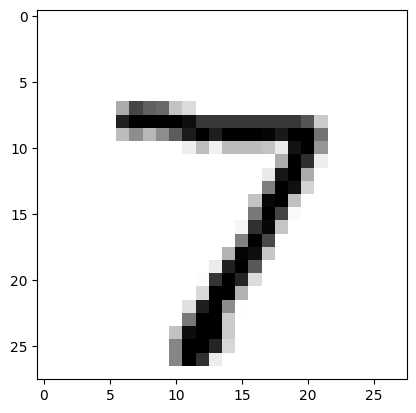

In [20]:
print("Label of this digit is:", test_labels[0])
plt.imshow(test_images[0,:,:,0], cmap=plt.cm.binary)
comet_model_2.log_figure(figure=plt)

It is! Let's visualize the classification results on the MNIST dataset. We will plot images from the test dataset along with their predicted label, as well as a histogram that provides the prediction probabilities for each of the digits:

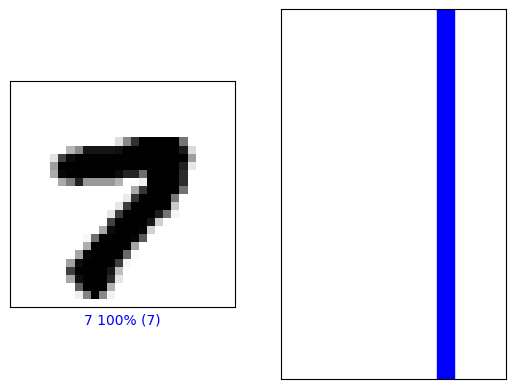

In [21]:
#@title Change the slider to look at the model's predictions! { run: "auto" }

image_index = 79 #@param {type:"slider", min:0, max:100, step:1}
plt.subplot(1,2,1)
mdl.lab2.plot_image_prediction(image_index, predictions, test_labels, test_images)
plt.subplot(1,2,2)
mdl.lab2.plot_value_prediction(image_index, predictions,  test_labels)
comet_model_2.log_figure(figure=plt)

We can also plot several images along with their predictions, where correct prediction labels are blue and incorrect prediction labels are grey. The number gives the percent confidence (out of 100) for the predicted label. Note the model can be very confident in an incorrect prediction!

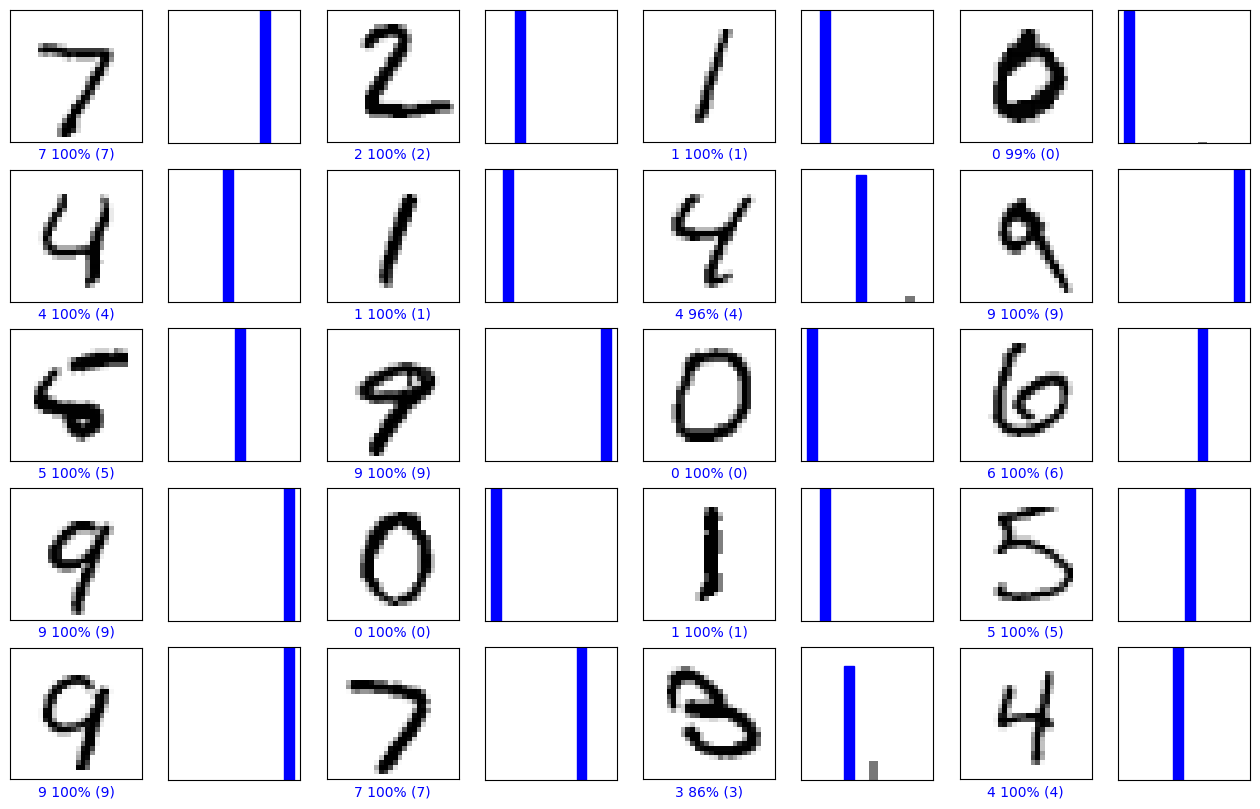

In [22]:
# Plots the first X test images, their predicted label, and the true label
# Color correct predictions in blue, incorrect predictions in red
num_rows = 5
num_cols = 4
num_images = num_rows*num_cols
plt.figure(figsize=(2*2*num_cols, 2*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  mdl.lab2.plot_image_prediction(i, predictions, test_labels, test_images)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  mdl.lab2.plot_value_prediction(i, predictions, test_labels)
comet_model_2.log_figure(figure=plt)
comet_model_2.end()

## 1.4 Training the model 2.0

Earlier in the lab, we used the [`fit`](https://www.tensorflow.org/api_docs/python/tf/keras/models/Sequential#fit) function call to train the model. This function is quite high-level and intuitive, which is really useful for simpler models. As you may be able to tell, this function abstracts away many details in the training call, and we have less control over training model, which could be useful in other contexts.

As an alternative to this, we can use the [`tf.GradientTape`](https://www.tensorflow.org/api_docs/python/tf/GradientTape) class to record differentiation operations during training, and then call the [`tf.GradientTape.gradient`](https://www.tensorflow.org/api_docs/python/tf/GradientTape#gradient) function to actually compute the gradients. You may recall seeing this in Lab 1 Part 1, but let's take another look at this here.

We'll use this framework to train our `cnn_model` using stochastic gradient descent.

GradientTape step 500 loss 0.44509291648864746


GradientTape step 1000 loss 0.294521689414978


GradientTape step 1500 loss 0.05323150381445885


GradientTape step 2000 loss 0.03988045081496239


GradientTape step 2500 loss 0.07824523001909256


GradientTape step 3000 loss 0.0075039975345134735


GradientTape step 3500 loss 0.012285709381103516


GradientTape step 4000 loss 0.07698718458414078


GradientTape step 4500 loss 0.23075194656848907


GradientTape step 5000 loss 0.005725093185901642


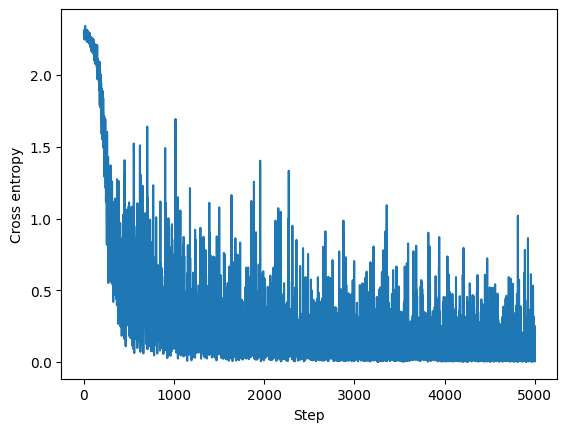

In [23]:
# Explicit GradientTape training on one complete shuffled pass of the 60,000 images.
cnn_model=build_cnn_model()
batch_size=12
optimizer=tf.keras.optimizers.SGD(learning_rate=.01)
@tf.function
def custom_train_step(images,labels):
    with tf.GradientTape() as tape:
        probabilities=cnn_model(images,training=True)
        loss=tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(labels,probabilities))
    gradients=tape.gradient(loss,cnn_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,cnn_model.trainable_variables))
    return loss

permutation=np.random.default_rng(42).permutation(len(train_images))
custom_history=[]; seen=0
for step,start in enumerate(range(0,len(train_images),batch_size)):
    idx=permutation[start:start+batch_size]
    loss=custom_train_step(train_images[idx],train_labels[idx])
    assert bool(tf.math.is_finite(loss)), 'Non-finite custom training loss'
    custom_history.append(dict(step=step+1,loss=float(loss))); seen+=len(idx)
    if (step+1)%500==0: print('GradientTape step',step+1,'loss',float(loss))
assert seen==60000
pd.DataFrame(custom_history).to_csv(RUN_DIR/'gradient_tape_training.csv',index=False)
custom_probabilities=cnn_model.predict(test_images,batch_size=128,verbose=0)
custom_test_acc=float(np.mean(custom_probabilities.argmax(1)==test_labels))
custom_test_loss=float(tf.reduce_mean(tf.keras.losses.sparse_categorical_crossentropy(test_labels,custom_probabilities)))
cnn_model.save(MODEL_DIR/'cnn_gradient_tape.keras')
record_task('gradient_tape_full_epoch',train_examples=seen,steps=len(custom_history),batch_size=batch_size,
            test_examples=10000,test_accuracy=custom_test_acc,test_loss=custom_test_loss)
plt.plot([r['step'] for r in custom_history],[r['loss'] for r in custom_history]); plt.xlabel('Step');plt.ylabel('Cross entropy')
plt.savefig(RUN_DIR/'gradient_tape_training.png');plt.show()

## 1.5 Conclusion
In this part of the lab, you had the chance to play with different MNIST classifiers with different architectures (fully-connected layers only, CNN), and experiment with how different hyperparameters affect accuracy (learning rate, etc.). The next part of the lab explores another application of CNNs, facial detection, and some drawbacks of AI systems in real world applications, like issues of bias.

Save your outputs

Run the following cell after finishing. Choose **File > Save** in Colab to preserve your code and displayed results. Files in `results/` and `models/` persist in Drive when enabled.

In [24]:
restored=tf.keras.models.load_model(MODEL_DIR/'cnn_mnist.keras', custom_objects={'softmax_v2': tf.keras.activations.softmax})
expected=predictions[:32]
np.testing.assert_allclose(restored.predict(test_images[:32],verbose=0),expected,rtol=1e-5,atol=1e-6)
record_task('checkpoint_round_trip',passed=True)
complete_notebook(['real_mnist_data','fc_optimizer_experiments','cnn_optimizer_experiments',
                   'fc_full_training_and_test','cnn_full_training_and_test','cnn_predictions',
                   'gradient_tape_full_epoch','checkpoint_round_trip'])

Saved run settings. Save the notebook in Colab to keep its cell outputs.
Required exercise checks passed. Artifacts: results/05_tf_lab2_mnist/20261010T124946-db93b0


In [25]:
# Added by the course runner: inspect the executed runtime, not coursework.
import os as _hailong_os, json as _hailong_json, platform as _hailong_platform
_hailong_evidence = {
    'python': _hailong_platform.python_version(),
    'quick_run': bool(globals().get('QUICK_RUN', False)),
    'course_smoke': _hailong_os.environ.get('COURSE_SMOKE', '0'),
    'keras_backend': _hailong_os.environ.get('KERAS_BACKEND'),
    'legacy_keras': _hailong_os.environ.get('TF_USE_LEGACY_KERAS'),
    'base_model_commit': getattr(getattr(globals().get('model'), 'config', None), '_commit_hash', None),
}
_hailong_context = globals().get('COLAB_CONTEXT')
if _hailong_context and _hailong_context['folder'].relative_to(_hailong_context['root']).as_posix().startswith(('03_fastai', '04_fastai_part2')):
    from course_persistence import collect_reuse_evidence as _hailong_collect
    _hailong_evidence['fastai_reuse_evidence'] = _hailong_context['run'].get('reuse_evidence') or _hailong_collect(_hailong_context)
print('__HAILONG_RUNTIME_EVIDENCE__' + _hailong_json.dumps(_hailong_evidence))


__HAILONG_RUNTIME_EVIDENCE__{"python": "3.12.13", "quick_run": false, "course_smoke": "0", "keras_backend": "tensorflow", "legacy_keras": null, "base_model_commit": null}
